<a href="https://colab.research.google.com/github/igornvidal/apollo_analytics_academy/blob/main/Taxa_de_Convers%C3%A3o_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

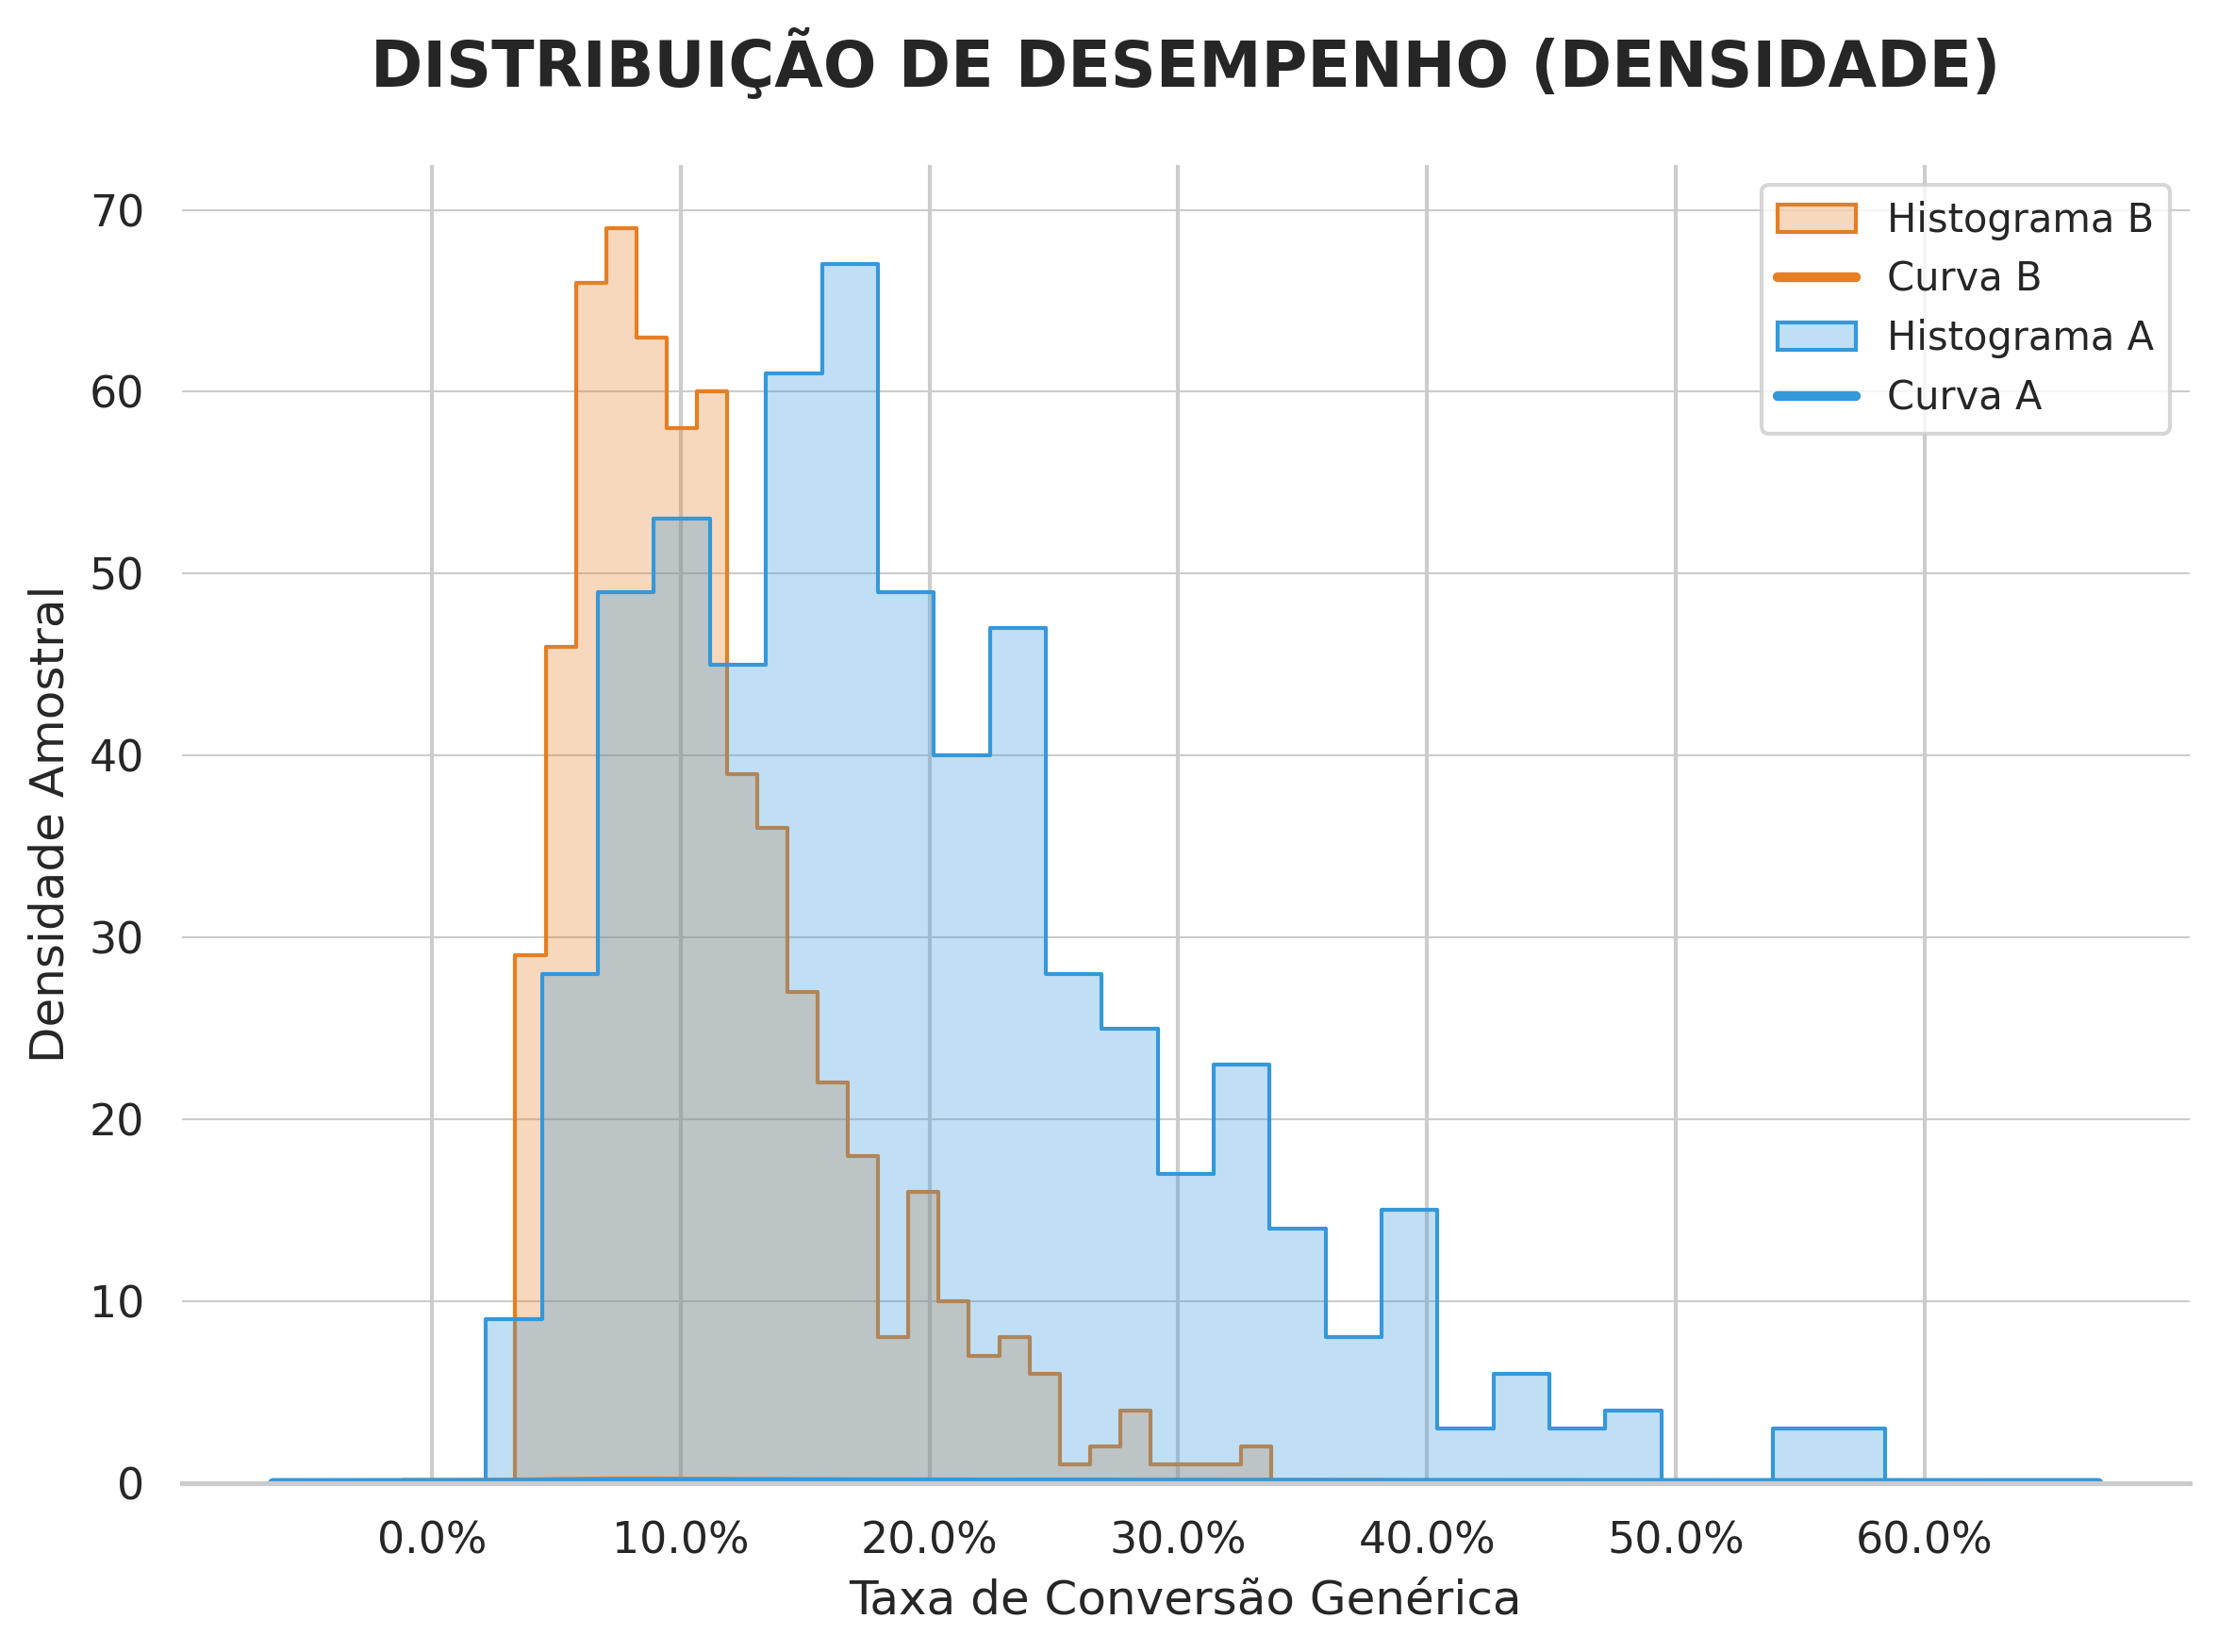

Códigos de exemplo prontos. Descomente as chamadas de função acima para gerar as imagens individualmente.


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats

# Configurações de estilo para o Instagram
plt.rcParams['figure.dpi'] = 300
sns.set_theme(style="whitegrid", palette="muted")
COLORS = ["#3498db", "#e67e22"] # Azul e Laranja para os grupos

# --- Gráfico de Dispersão ---
def plot_scatter():
    np.random.seed(42)
    group_b_perf = np.random.uniform(2, 35, 300)

    # Criando correlação e lift para Grupo A (simulando "com IA")
    group_a_perf = 1.05 * group_b_perf + np.random.normal(5, 4, 300)
    # Limitando para simular taxas de conversão realistas (0-100%)
    group_a_perf = np.clip(group_a_perf, 0, 60)
    group_b_perf = np.clip(group_b_perf, 0, 60)

    slope, intercept, r_value, _, _ = stats.linregress(group_b_perf, group_a_perf)

    plt.figure(figsize=(8, 6))

    # Gráfico de dispersão
    plt.scatter(group_b_perf, group_a_perf, alpha=0.6, color=COLORS[0], s=30)

    # Linha de tendência
    x_range = np.array([0, 60])
    plt.plot(x_range, slope * x_range + intercept, color="#e74c3c", linewidth=2.5,
             label=f'y={slope:.2f}x + {intercept:.2f}')

    plt.title("RELAÇÃO DE DESEMPENHO DOS GRUPOS (r=0.750)", fontsize=16, fontweight='bold', pad=20)
    plt.ylabel("Métrica de Desempenho - Grupo A", fontsize=12)
    plt.xlabel("Métrica de Desempenho - Grupo B", fontsize=12)
    plt.xticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])
    plt.yticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])
    plt.legend(frameon=True, fontsize=10)
    plt.grid(True, which='major', linestyle='--', linewidth=0.5)
    plt.tight_layout()
    plt.savefig('scatter_performance.png')
    plt.show()

# --- Gráfico de Barras ---
def plot_bars():
    # Usando valores genéricos "X" e "Y" (próximos aos originais)
    data_gen = {'Grupo A': 11.0, 'Grupo B': 9.5}
    grupos = list(data_gen.keys())
    valores = list(data_gen.values())

    plt.figure(figsize=(7, 5))
    bars = plt.bar(grupos, valores, color=COLORS, width=0.6)

    # Adicionar rótulos
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 0.3, f"{yval:.1f}%",
                 ha='center', va='bottom', fontsize=12, fontweight='bold')

    plt.title("MÉDIA DE DESEMPENHO COMPARATIVA", fontsize=16, fontweight='bold', pad=15)
    plt.suptitle("Volume Amostral Superior a 50 Pontos de Dados\nDiferença Média (∆) = 1.5 pp", fontsize=11, y=0.92)
    plt.ylabel("Taxa de Conversão Geral", fontsize=12)
    plt.xticks(fontsize=11)
    plt.yticks(np.arange(0, 15, 2), [f"{i}.0%" for i in np.arange(0, 15, 2)], fontsize=10)
    plt.ylim(0, 14)
    plt.grid(axis='y', linestyle='-', linewidth=0.5)
    sns.despine(left=True)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig('bars_performance.png')
    plt.show()

# --- Gráfico Q-Q (com setas de lift) ---
def plot_qq():
    np.random.seed(42)
    # Amostras não-normais
    data_b_perf = stats.gamma.rvs(a=2, loc=5, scale=5, size=500)
    # Grupo A é Grupo B com um 'lift' constante
    data_a_perf = data_b_perf + np.random.normal(7, 2, 500)

    # Clipar para simular taxas
    data_a_perf = np.clip(data_a_perf, 0, 60)
    data_b_perf = np.clip(data_b_perf, 0, 60)

    percs = np.linspace(0, 100, 100)
    qn_a = np.percentile(data_a_perf, percs)
    qn_b = np.percentile(data_b_perf, percs)

    plt.figure(figsize=(8, 7))
    plt.plot(qn_b, qn_a, marker='o', linestyle='none', color=COLORS[0], markersize=5, label='Quantis Calculados')

    # Linha de igualdade (45 graus)
    lims = [0, 60]
    plt.plot(lims, lims, '--', color="#e74c3c", linewidth=2, label='Linha de Igualdade (45°)')

    # Adicionar setas de 'lift' (ex: quantis 30, 50, 70)
    arrow_indices = [30, 50, 70]
    for idx in arrow_indices:
        x, y = qn_b[idx], qn_a[idx]
        plt.annotate('', xy=(x + 0.5, y + 0.5), xytext=(x + 2, y + 2),
                    arrowprops=dict(facecolor='black', edgecolor='black', width=1, headwidth=6, shrink=0.05))

    plt.title("GRÁFICO DE QUANTIS (Q-Q)", fontsize=16, fontweight='bold', pad=20)
    plt.ylabel("Quantis - Métrica de Desempenho (Grupo A)", fontsize=12)
    plt.xlabel("Quantis - Métrica de Desempenho (Grupo B)", fontsize=12)
    plt.xticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])
    plt.yticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])
    plt.legend(frameon=True, fontsize=10)
    plt.grid(True, linestyle='--', linewidth=0.5)
    plt.tight_layout()
    plt.savefig('qq_plot_performance.png')
    plt.show()

# --- Gráfico de Densidade/Histograma (reproduzindo image_3) ---
def plot_density():
    np.random.seed(42)
    # Criando distribuições que imitam a imagem original
    # Grupo B (Orange, original SEMIA)
    data_b_perf = stats.gamma.rvs(a=2, loc=3, scale=4, size=600)
    # Grupo A (Blue, original CIA, mais "espalhada" e com média maior)
    data_a_perf = stats.gamma.rvs(a=3, loc=1, scale=6, size=600)

    # Clipar para simular taxas
    data_a_perf = np.clip(data_a_perf, 0, 60)
    data_b_perf = np.clip(data_b_perf, 0, 60)

    plt.figure(figsize=(8, 6))

    # Histogramas e KDEs misturados
    sns.histplot(data_b_perf, bins=25, kde=False, color=COLORS[1], element="step", alpha=0.3, label="Histograma B")
    sns.kdeplot(data_b_perf, color=COLORS[1], linewidth=2.5, label="Curva B")

    sns.histplot(data_a_perf, bins=25, kde=False, color=COLORS[0], element="step", alpha=0.3, label="Histograma A")
    sns.kdeplot(data_a_perf, color=COLORS[0], linewidth=2.5, label="Curva A")

    plt.title("DISTRIBUIÇÃO DE DESEMPENHO (DENSIDADE)", fontsize=16, fontweight='bold', pad=20)
    plt.ylabel("Densidade Amostral", fontsize=12)
    plt.xlabel("Taxa de Conversão Genérica", fontsize=12)
    plt.xticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])
    plt.legend(frameon=True, fontsize=10)
    plt.grid(True, axis='y', linestyle='-', linewidth=0.5)
    sns.despine(left=True)
    plt.tight_layout()
    plt.savefig('density_plot_performance.png')
    plt.show()

# Executar as funções para gerar e salvar as imagens limpas
# plot_scatter() # Gera e salva 'scatter_performance.png'
# plot_bars()    # Gera e salva 'bars_performance.png'
# plot_qq()      # Gera e salva 'qq_plot_performance.png'
plot_density() # Gera e salva 'density_plot_performance.png'

print("Códigos de exemplo prontos. Descomente as chamadas de função acima para gerar as imagens individualmente.")

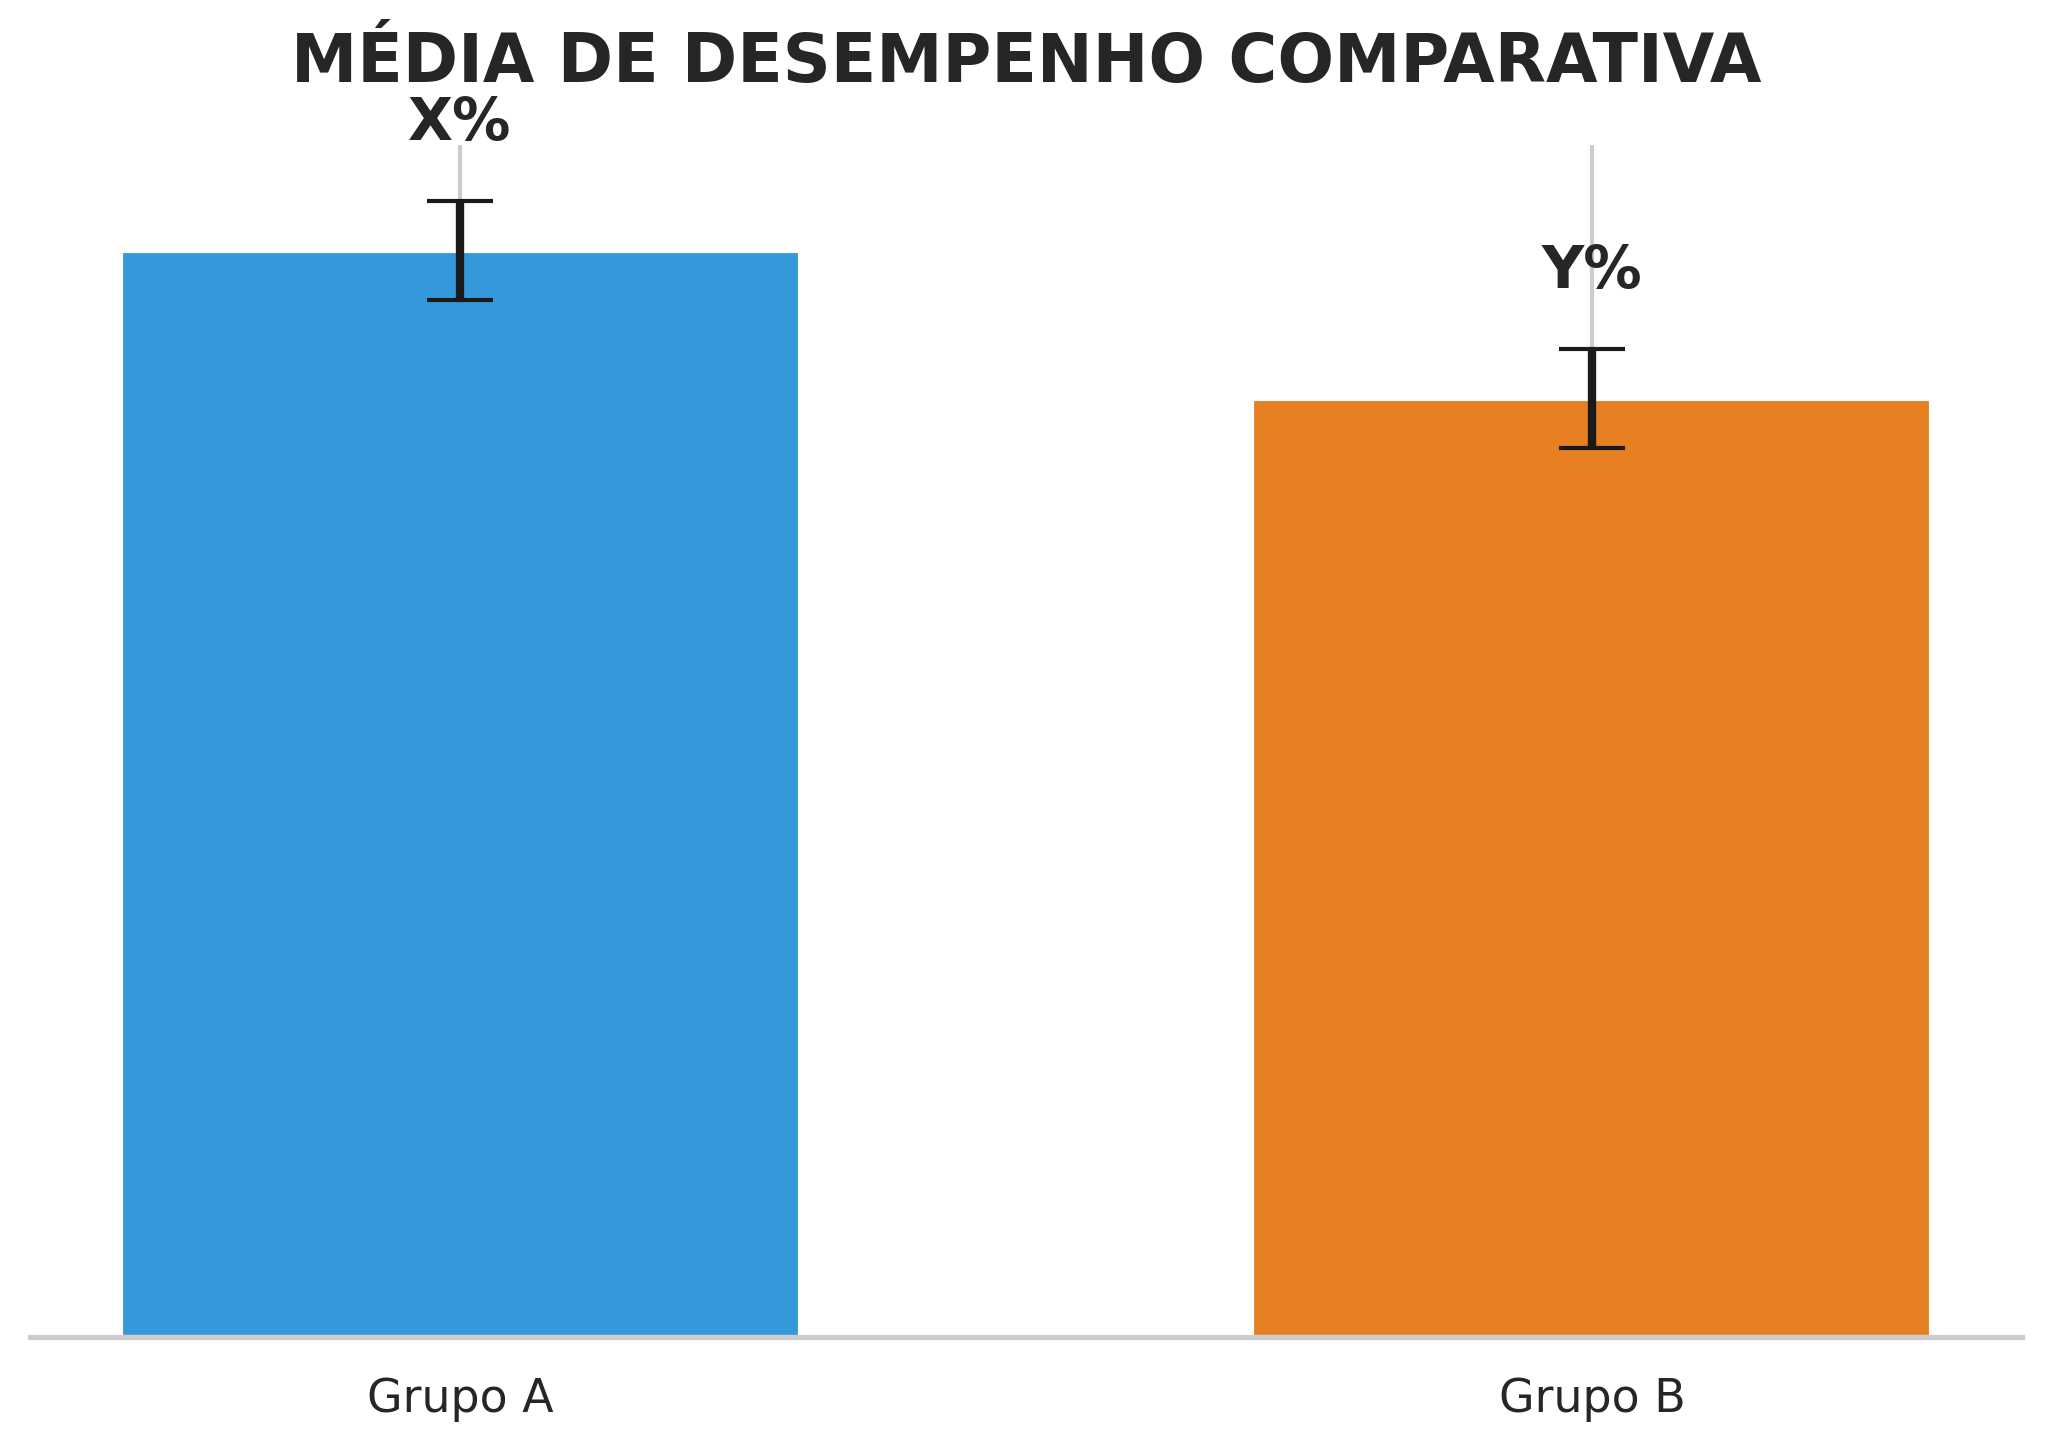

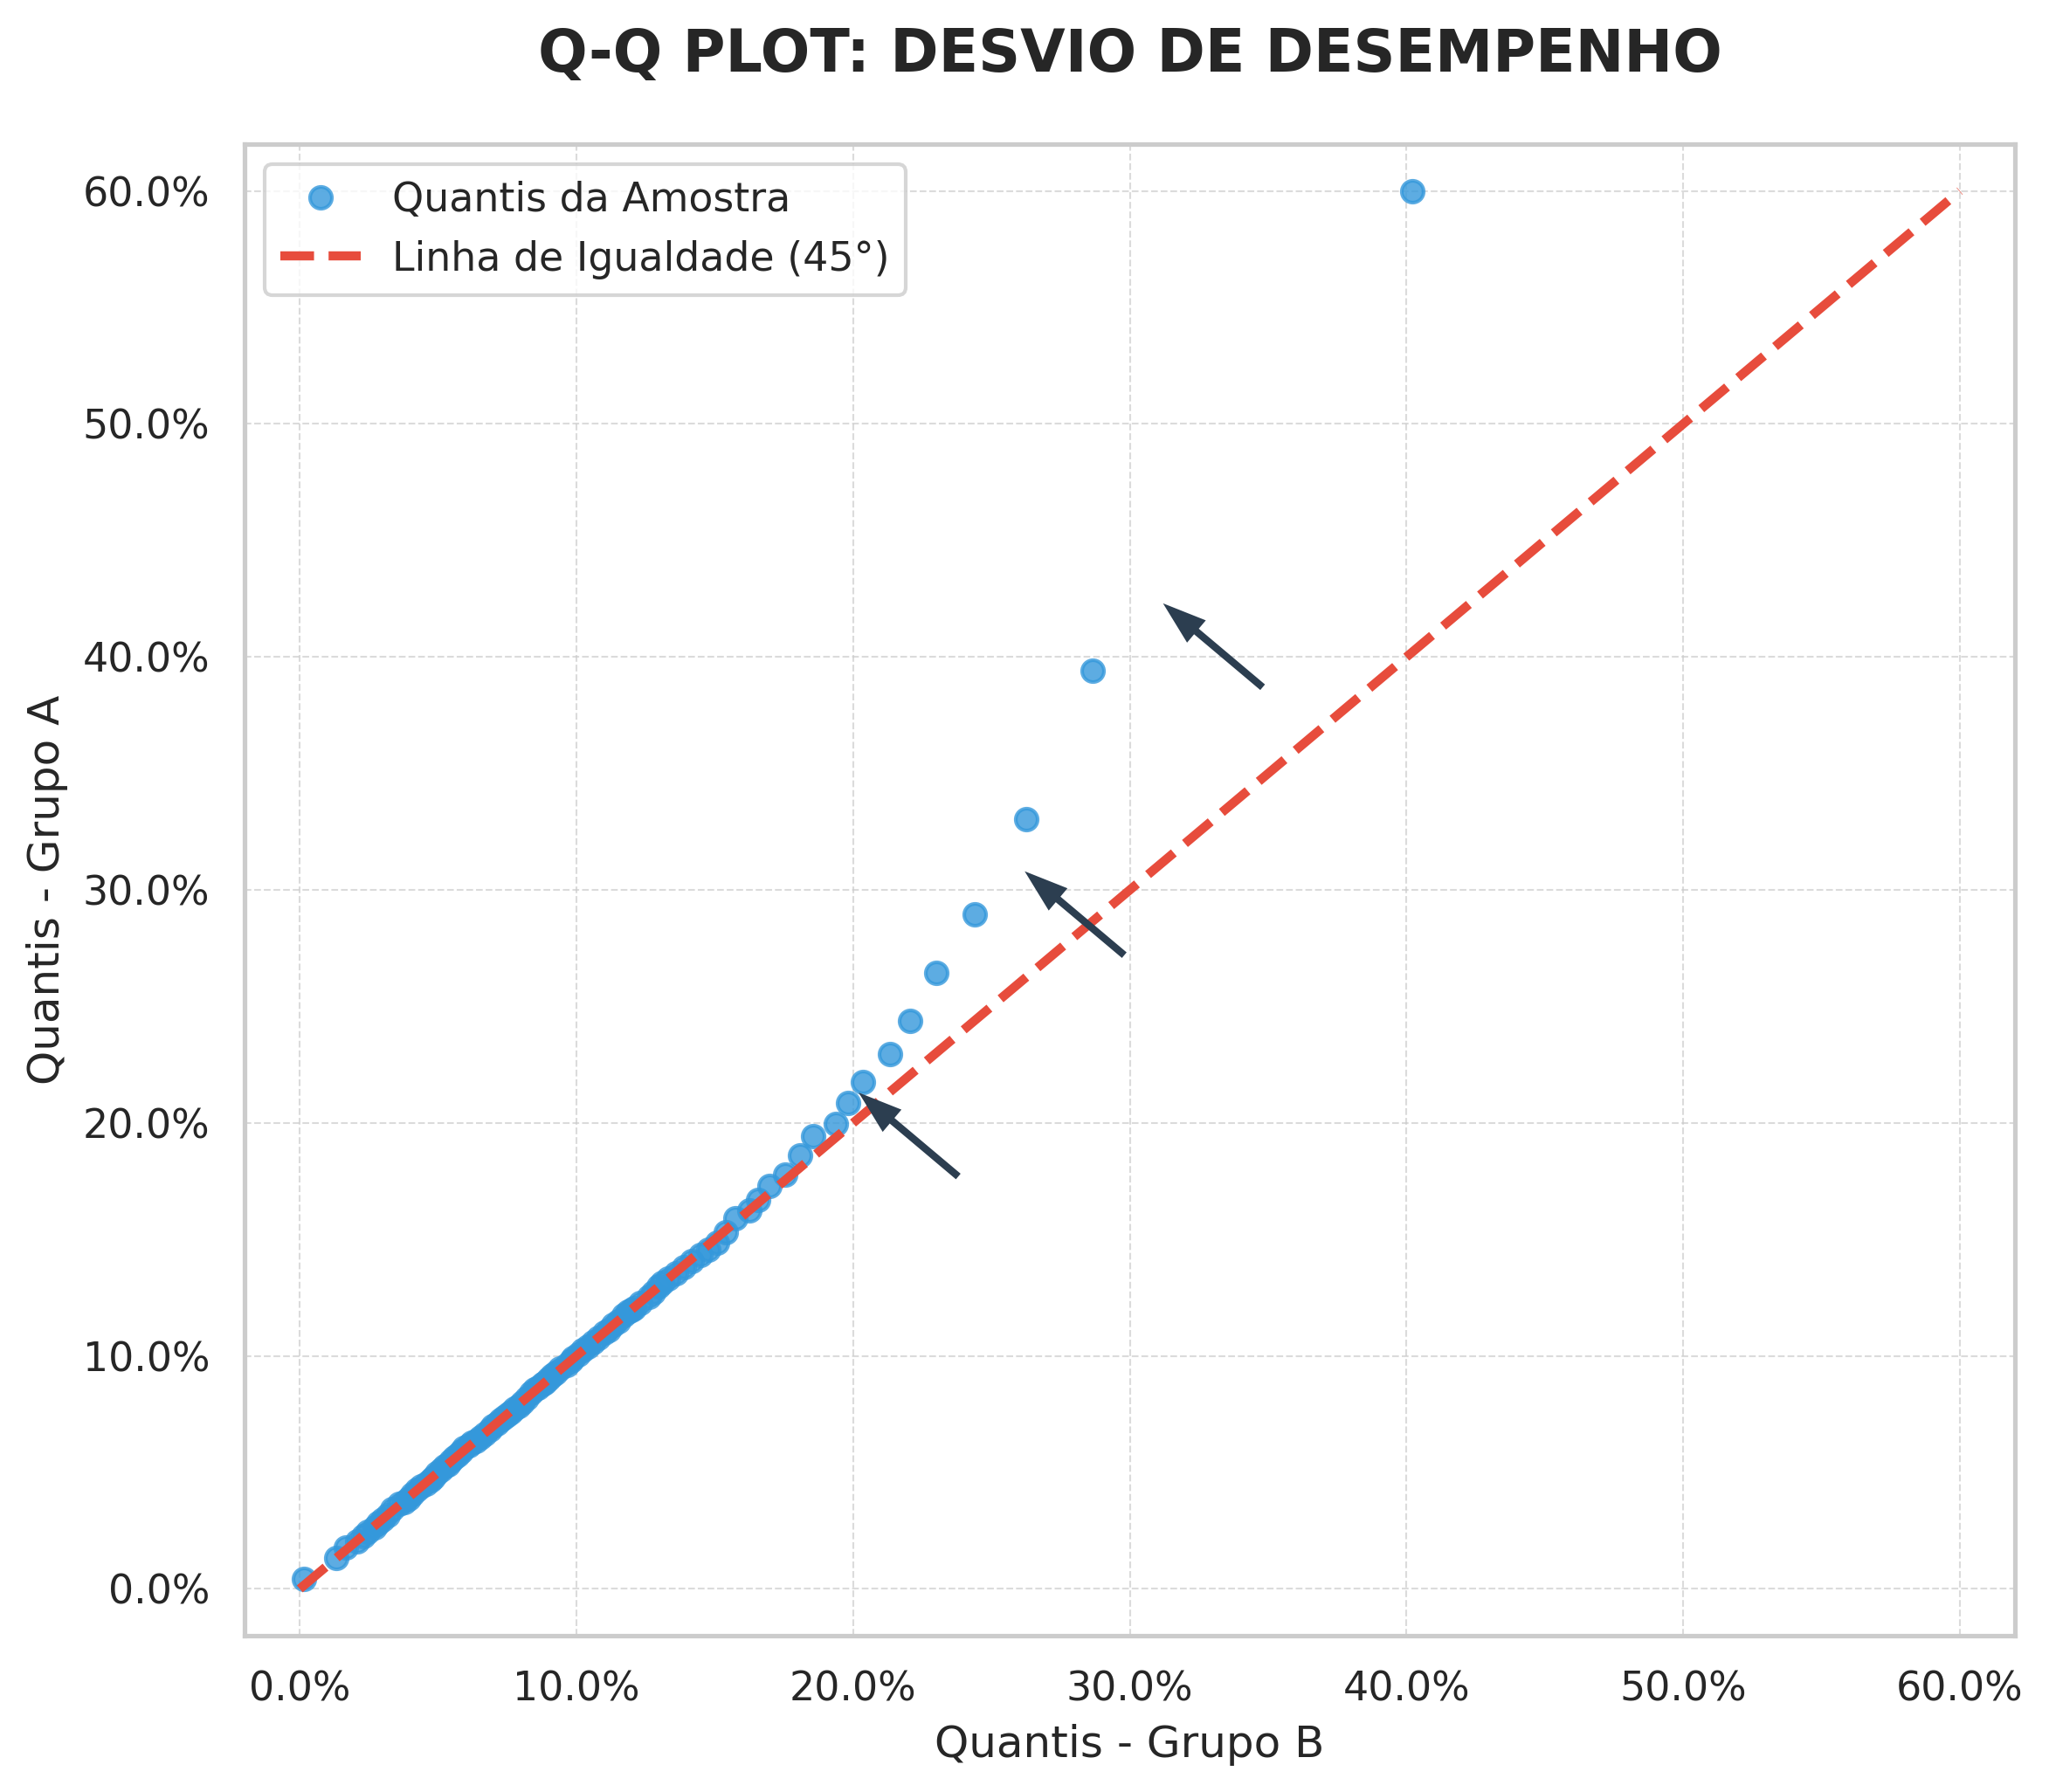

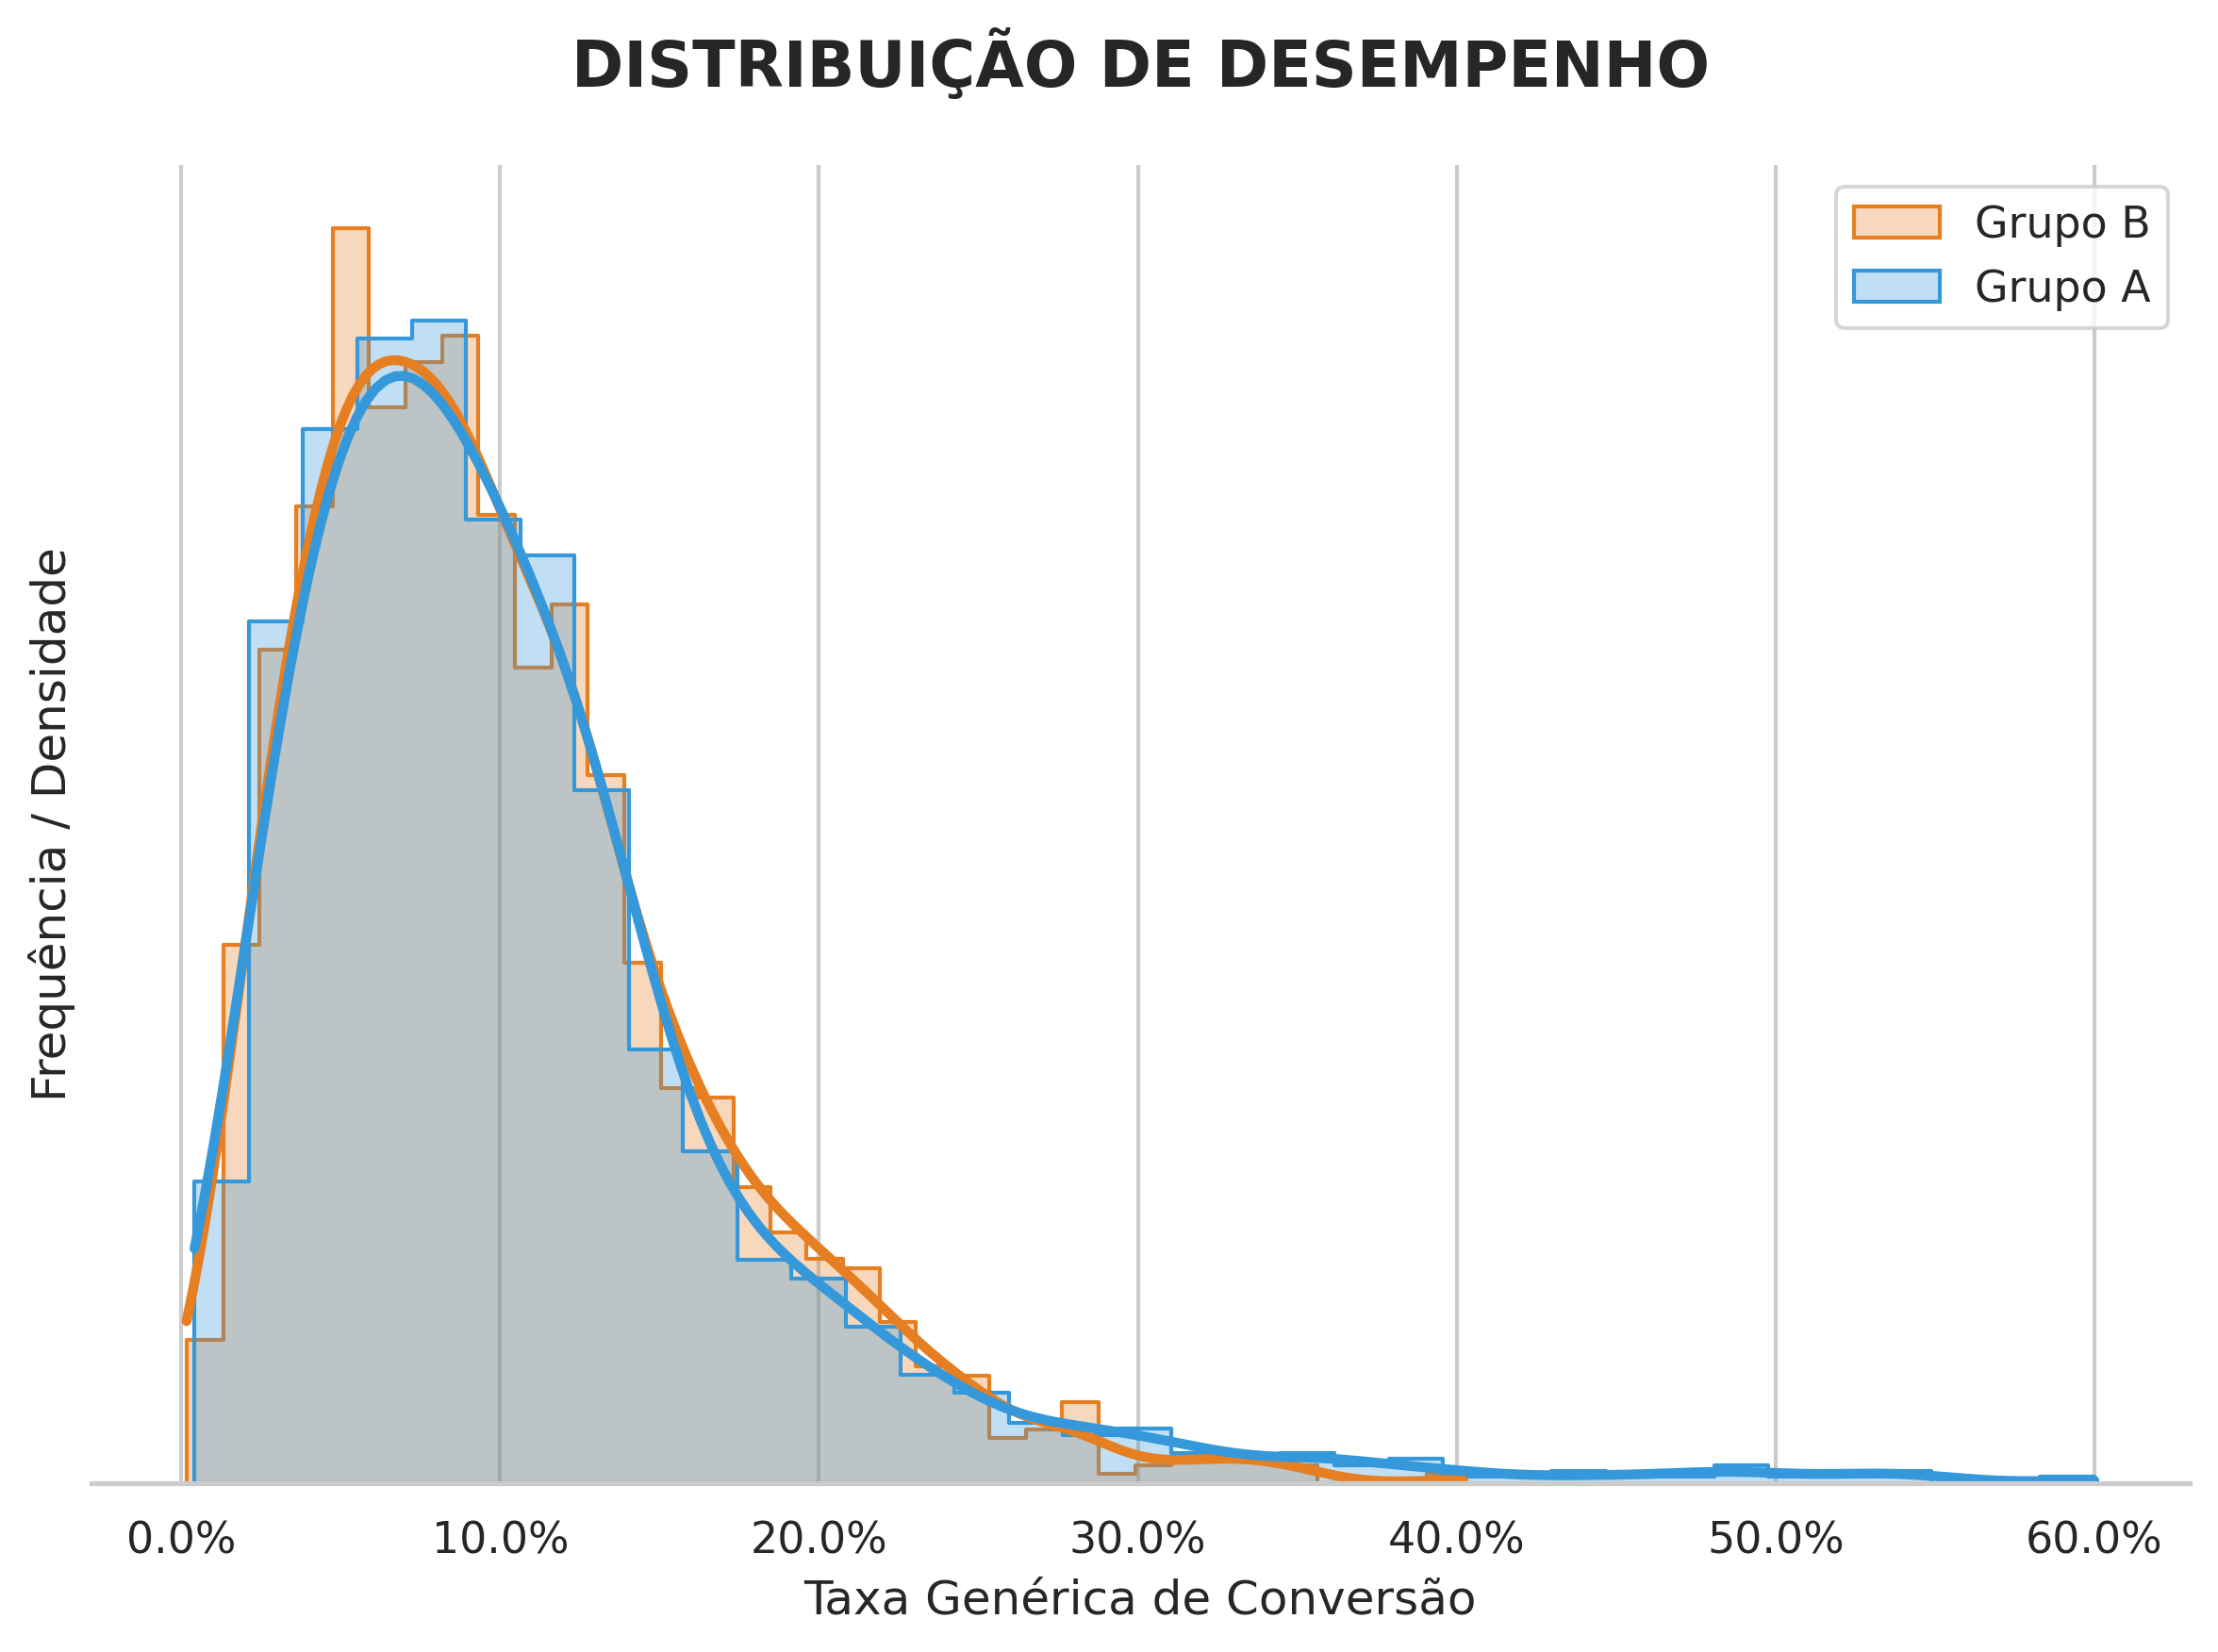

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats

# Configurações de estilo
plt.rcParams['figure.dpi'] = 300
sns.set_theme(style="whitegrid", palette="muted")
COLORS = ["#3498db", "#e67e22"] # Azul (Grupo A) e Laranja (Grupo B)

# ==========================================
# 1. GRÁFICO DE BARRAS (Omitindo Eixo Y e Valores)
# ==========================================
def plot_bars():
    grupos = ['Grupo A', 'Grupo B']
    valores = [11.0, 9.5]
    erros = [0.5, 0.5] # Intervalo de confiança de 0.5 pp
    labels = ["X%", "Y%"] # Rótulos genéricos

    plt.figure(figsize=(7, 5))

    # Capsize define o "chapeuzinho" da barra de erro
    bars = plt.bar(grupos, valores, yerr=erros, color=COLORS,
                   width=0.6, capsize=8, error_kw={'linewidth': 2})

    # Retirando o eixo Y completamente para ocultar a escala
    ax = plt.gca()
    ax.get_yaxis().set_visible(False)
    sns.despine(left=True, bottom=False)

    # Adicionando os rótulos X% e Y% acima das barras de erro
    for bar, label in zip(bars, labels):
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 1.0, label,
                 ha='center', va='bottom', fontsize=14, fontweight='bold')

    plt.title("MÉDIA DE DESEMPENHO COMPARATIVA", fontsize=16, fontweight='bold', pad=15)
    plt.tight_layout()
    plt.savefig('bars_instagram.png')
    plt.show()

# ==========================================
# GERAÇÃO DE DADOS (Simulando o Q-Q Real)
# ==========================================
np.random.seed(42)
# Grupo B: Maior concentração no início (pico em ~8%), caindo depois
data_b = np.random.gamma(shape=2.5, scale=4.0, size=1500)
data_b = np.clip(data_b, 0, 60)

# Grupo A: Anda junto com B até 15. Depois, acelera exponencialmente para a esquerda.
# Isso vai recriar perfeitamente a inflexão do seu Q-Q Plot original.
data_a = np.where(data_b <= 15,
                  data_b + np.random.normal(0, 0.3, len(data_b)),
                  data_b + 0.05 * (data_b - 15)**2 + np.random.normal(0, 1.0, len(data_b)))
data_a = np.clip(data_a, 0, 60)

# ==========================================
# 2. Q-Q PLOT (Com a inflexão realista)
# ==========================================
def plot_qq():
    percs = np.linspace(0, 100, 100)
    qn_a = np.percentile(data_a, percs)
    qn_b = np.percentile(data_b, percs)

    plt.figure(figsize=(8, 7))
    plt.plot(qn_b, qn_a, marker='o', linestyle='none', color=COLORS[0],
             markersize=6, alpha=0.8, label='Quantis da Amostra')

    # Linha de igualdade (45 graus)
    lims = [0, 60]
    plt.plot(lims, lims, '--', color="#e74c3c", linewidth=2.5, label='Linha de Igualdade (45°)')

    # Setas ilustrativas copiando o padrão da sua imagem original
    arrow_props = dict(facecolor='#2c3e50', shrink=0.05, width=2, headwidth=8, edgecolor='none')
    plt.annotate('', xy=(20, 21.5), xytext=(24, 17.5), arrowprops=arrow_props)
    plt.annotate('', xy=(26, 31), xytext=(30, 27), arrowprops=arrow_props)
    plt.annotate('', xy=(31, 42.5), xytext=(35, 38.5), arrowprops=arrow_props)

    plt.title("Q-Q PLOT: DESVIO DE DESEMPENHO", fontsize=16, fontweight='bold', pad=20)
    plt.ylabel("Quantis - Grupo A", fontsize=12)
    plt.xlabel("Quantis - Grupo B", fontsize=12)
    plt.xticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])
    plt.yticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])
    plt.xlim(-2, 62)
    plt.ylim(-2, 62)
    plt.legend(frameon=True, fontsize=11, loc='upper left')
    plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
    plt.tight_layout()
    plt.savefig('qq_instagram.png')
    plt.show()

# ==========================================
# 3. HISTOGRAMA + KDE (Curvas corrigidas)
# ==========================================
def plot_density():
    plt.figure(figsize=(8, 6))

    # O segredo aqui é o stat="density" combinado com kde=True no Seaborn
    sns.histplot(data_b, bins=35, stat="density", kde=True, color=COLORS[1],
                 element="step", alpha=0.3, line_kws={'linewidth': 2.5}, label="Grupo B")

    sns.histplot(data_a, bins=35, stat="density", kde=True, color=COLORS[0],
                 element="step", alpha=0.3, line_kws={'linewidth': 2.5}, label="Grupo A")

    plt.title("DISTRIBUIÇÃO DE DESEMPENHO", fontsize=16, fontweight='bold', pad=20)
    plt.xlabel("Taxa Genérica de Conversão", fontsize=12)
    plt.xticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])

    # Removendo os rótulos do eixo Y (densidade não significa muito pro público do Instagram)
    plt.ylabel("Frequência / Densidade", fontsize=12)
    plt.yticks([])

    plt.legend(frameon=True, fontsize=11)
    plt.grid(True, axis='y', linestyle='--', linewidth=0.5, alpha=0.5)
    sns.despine(left=True)
    plt.tight_layout()
    plt.savefig('density_instagram.png')
    plt.show()

# Executando as funções
plot_bars()
plot_qq()
plot_density()

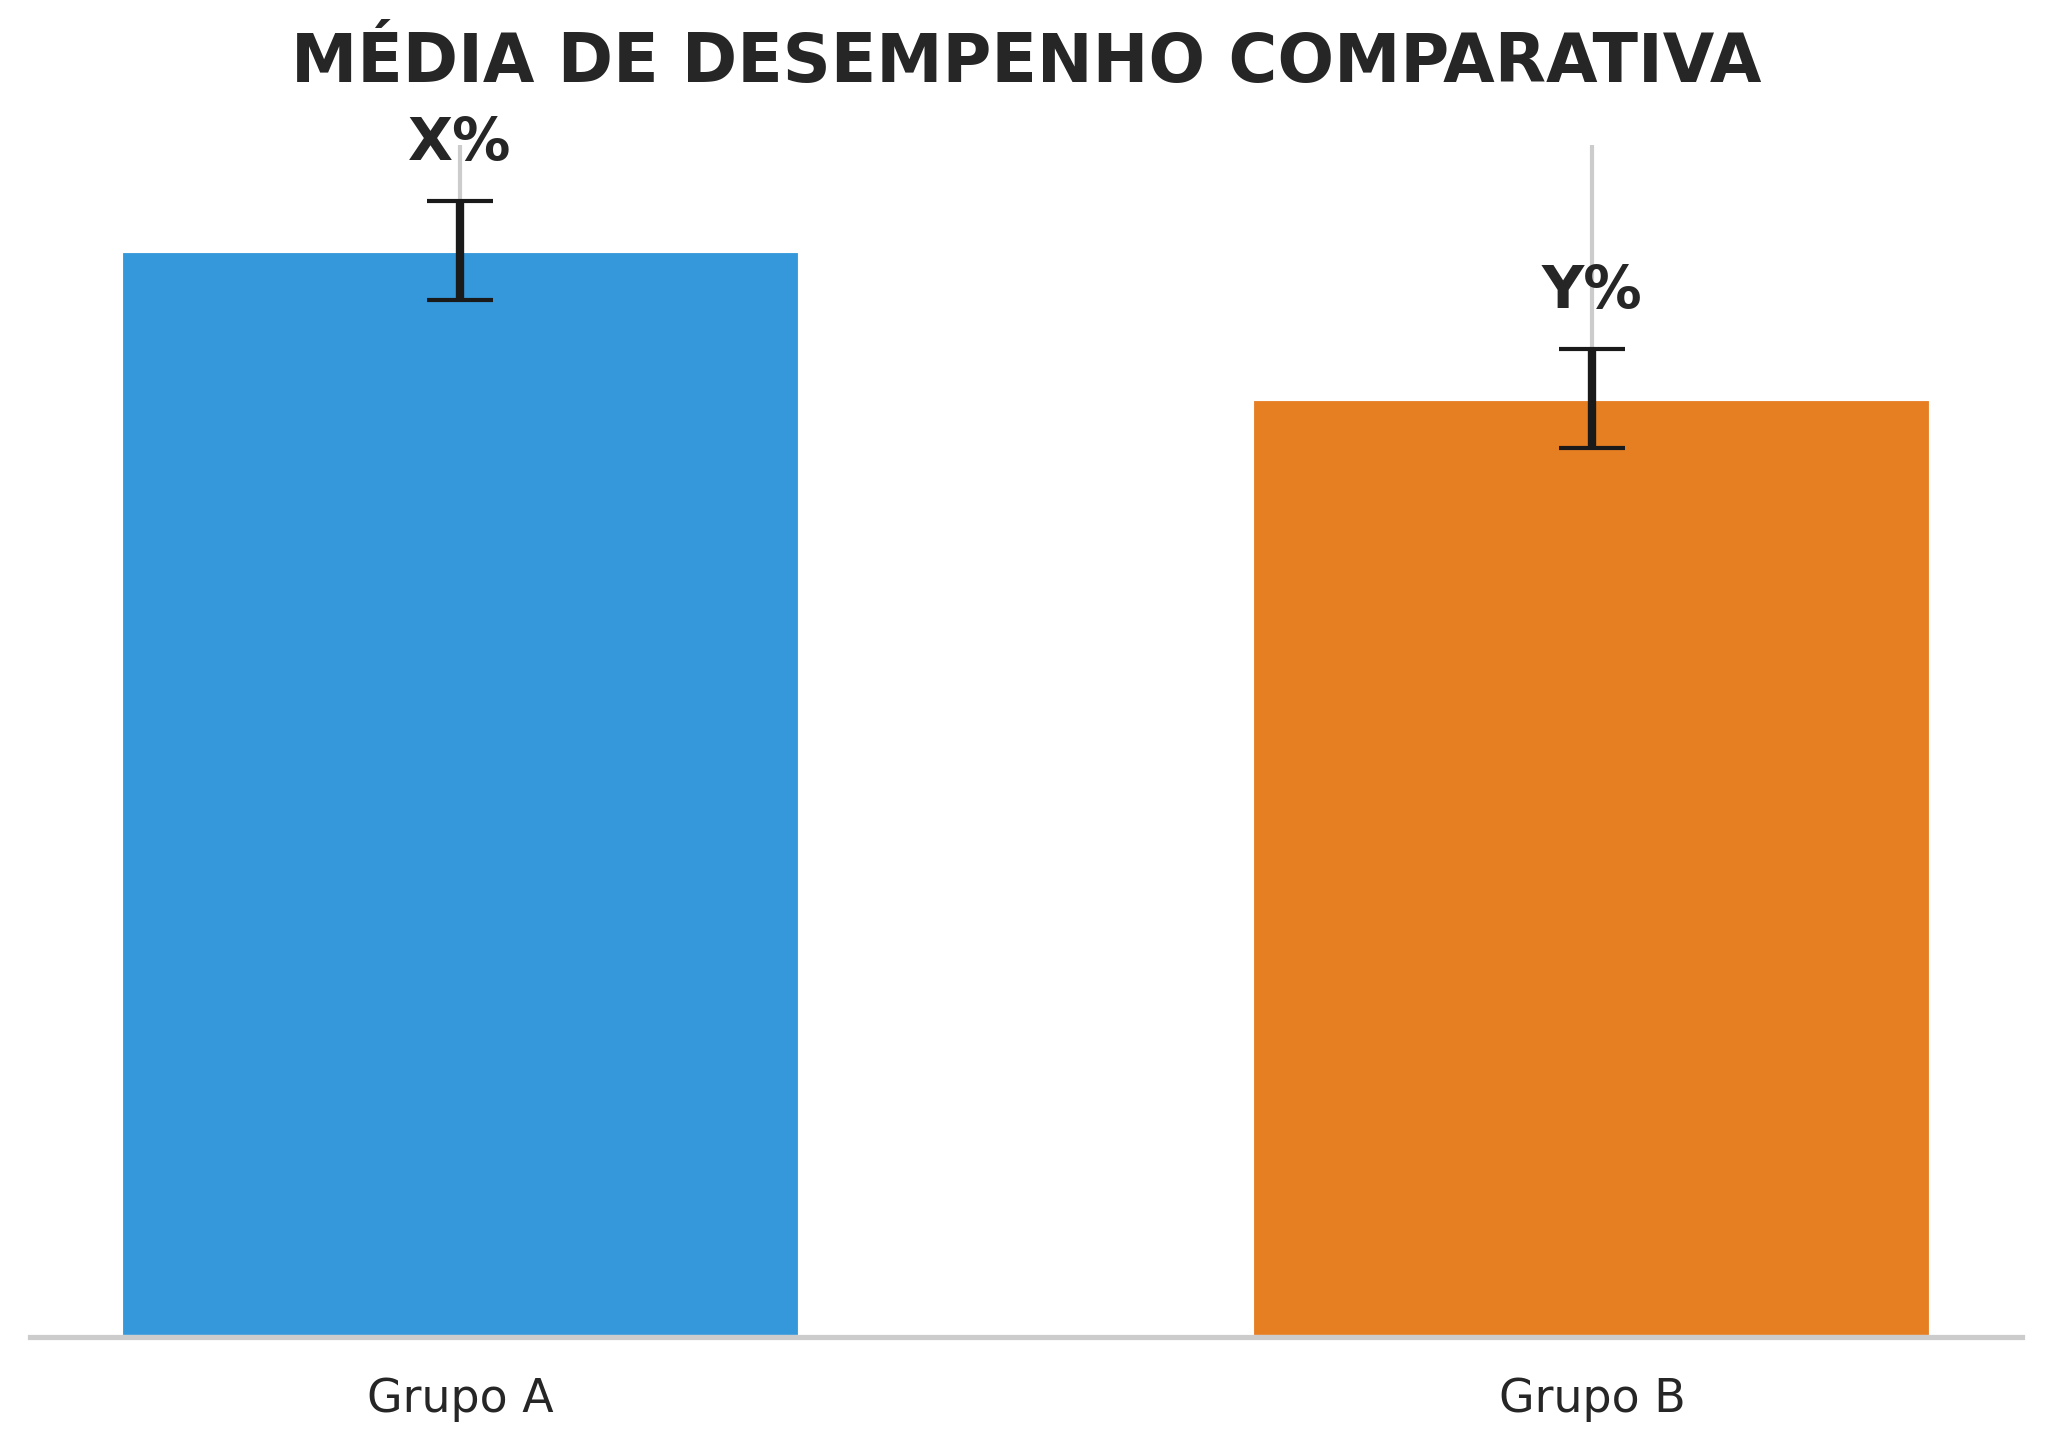

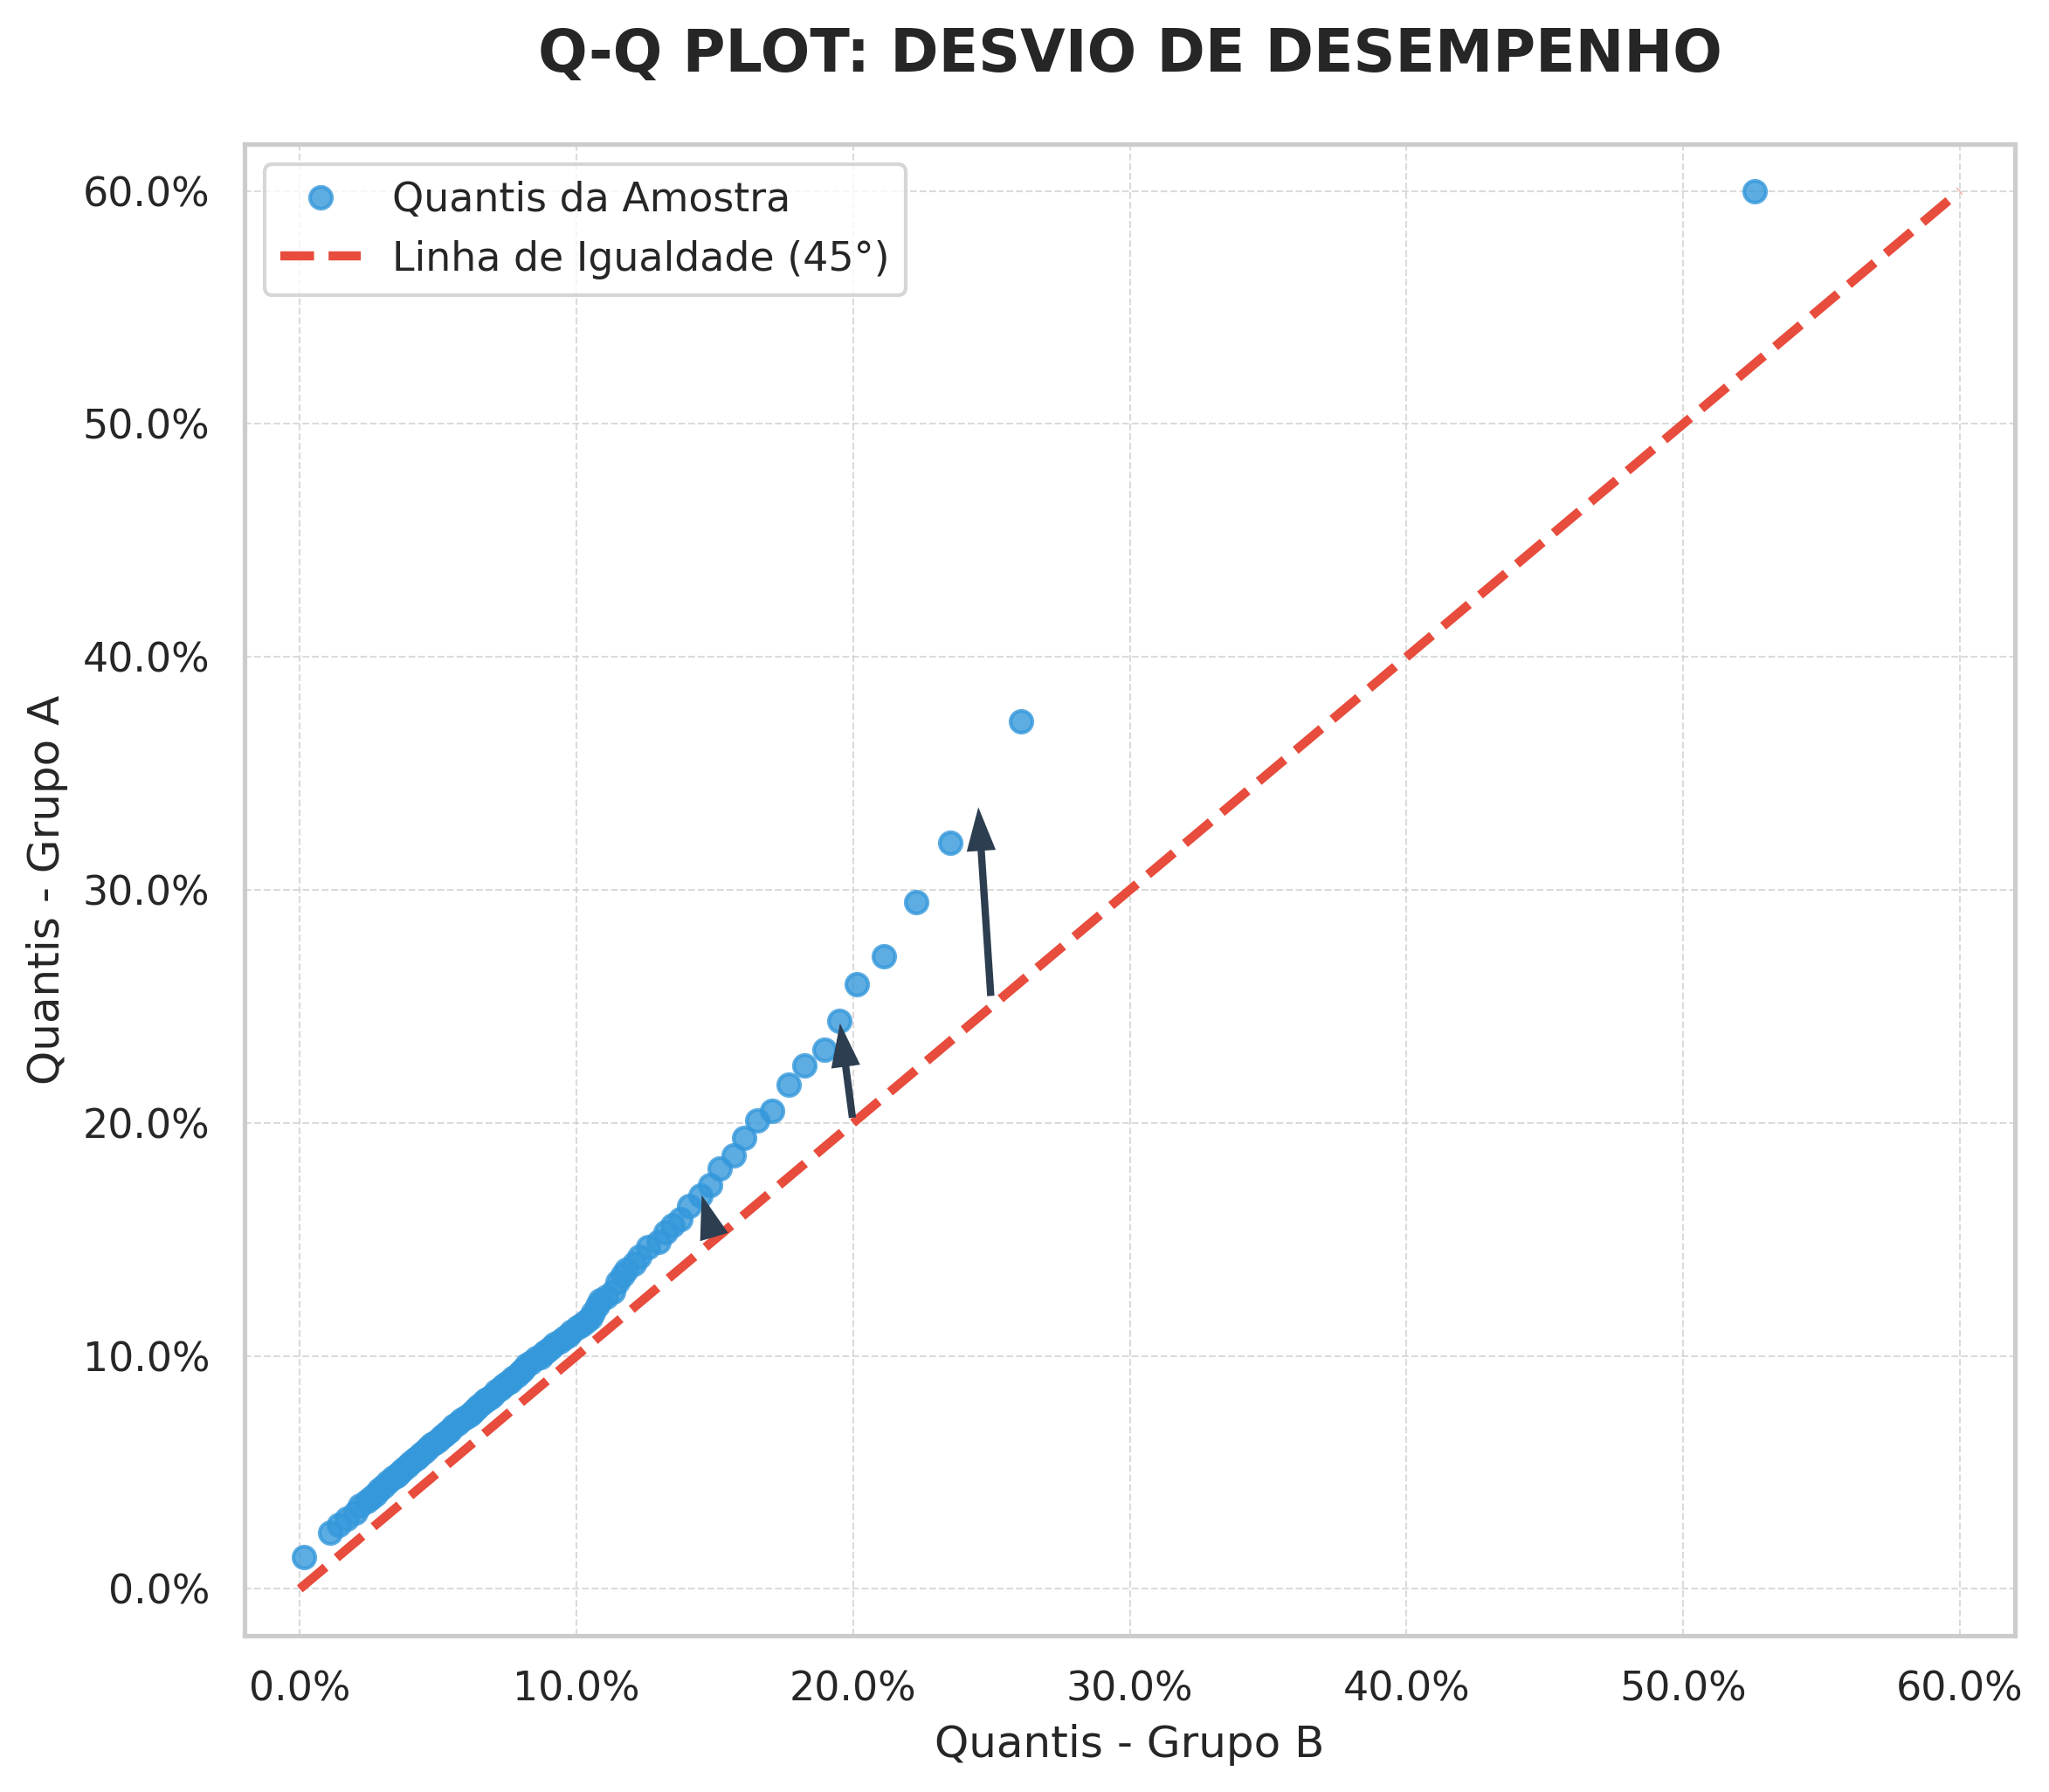

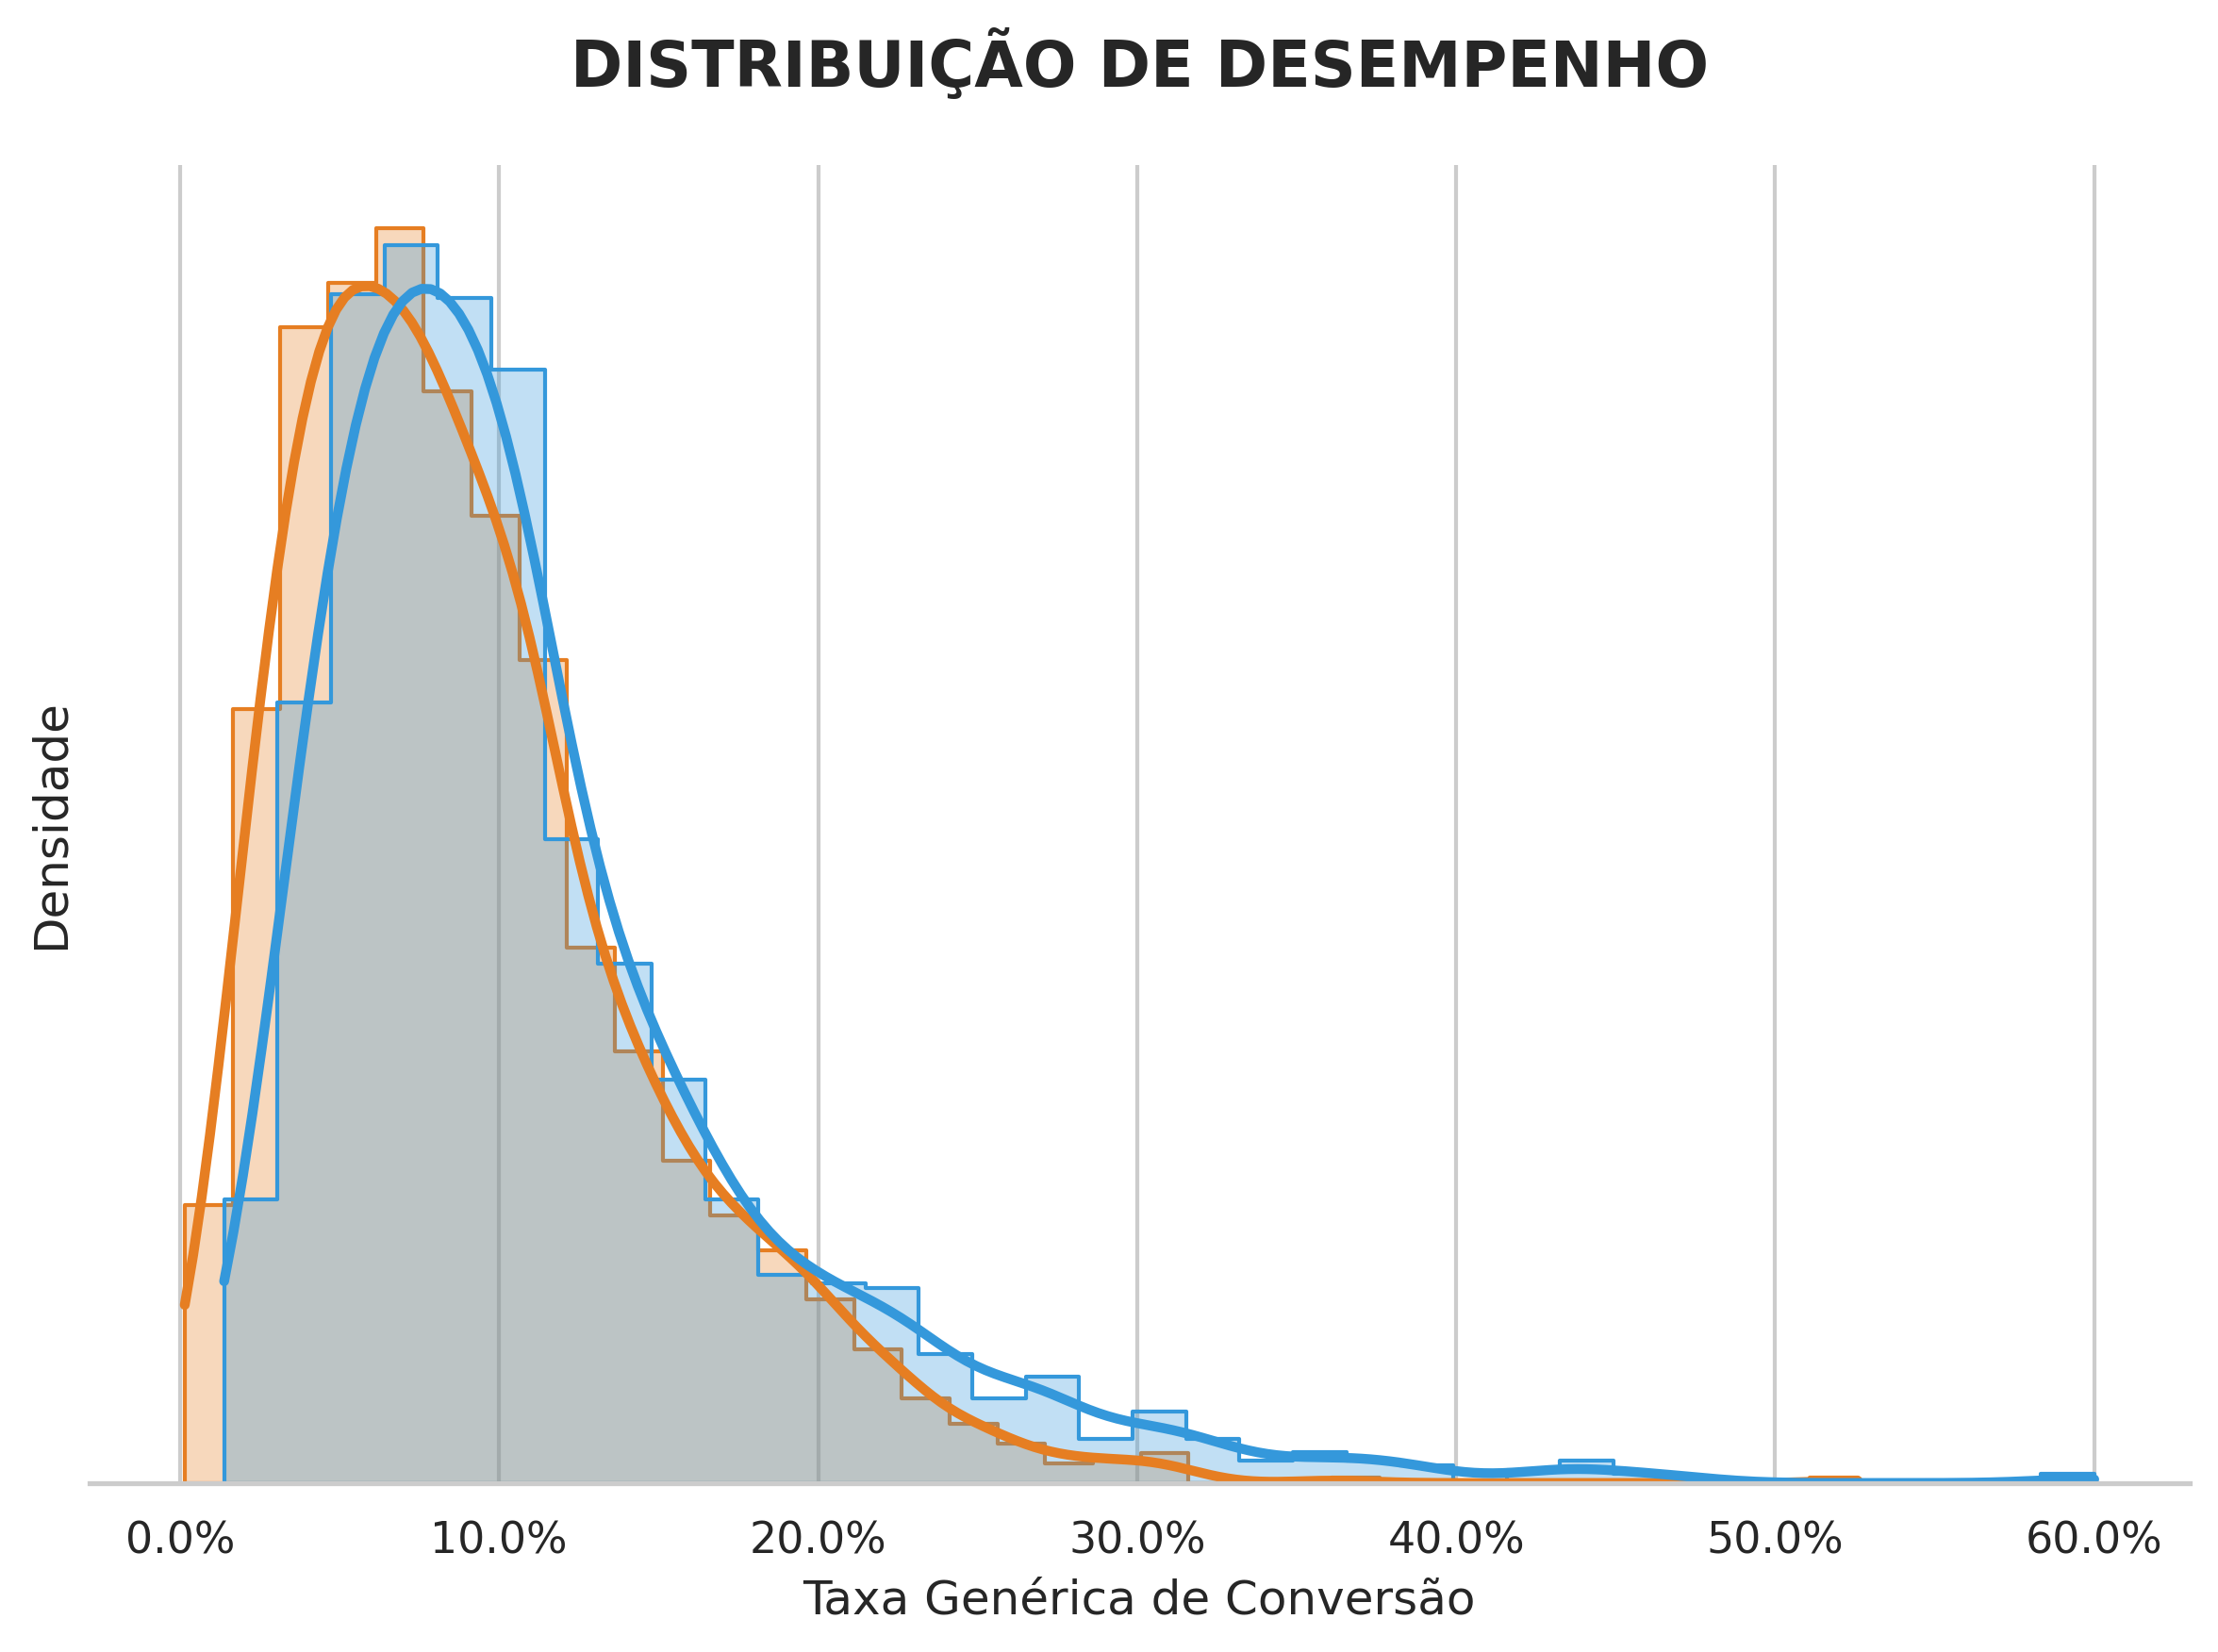

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Configurações de estilo
plt.rcParams['figure.dpi'] = 300
sns.set_theme(style="whitegrid", palette="muted")
COLORS = ["#3498db", "#e67e22"] # Azul (Grupo A) e Laranja (Grupo B)

# ==========================================
# GERAÇÃO ÚNICA DE DADOS PARA TODOS OS GRÁFICOS
# ==========================================
np.random.seed(42)

# Grupo B: Concentração maior no início, cauda caindo naturalmente
data_b = np.random.gamma(shape=2.5, scale=3.6, size=2000)

# Grupo A: Anda idêntico ao B até o threshold (10%), depois sofre a aceleração quadrática
threshold = 10
base_shift_a = 1.4 # Ajuste para que a mediana do Grupo A seja de aproximadamente 10%
data_a = np.where(
    data_b <= threshold,
    data_b + base_shift_a + np.random.normal(0, 0.4, len(data_b)), # Ruído mínimo, andam juntos
    data_b + base_shift_a + 0.06 * (np.maximum(0, data_b - threshold))**1.8 + np.random.normal(0, 1.2, len(data_b)) # Aceleração
)

# Limitando entre 0 e 60 para simular a escala de porcentagem
data_a = np.clip(data_a, 0, 60)
data_b = np.clip(data_b, 0, 60)

# ==========================================
# 1. GRÁFICO DE BARRAS
# ==========================================
def plot_bars():
    grupos = ['Grupo A', 'Grupo B']
    valores = [11.0, 9.5]
    erros = [0.5, 0.5]
    labels = ["X%", "Y%"]

    plt.figure(figsize=(7, 5))
    bars = plt.bar(grupos, valores, yerr=erros, color=COLORS,
                   width=0.6, capsize=8, error_kw={'linewidth': 2})

    ax = plt.gca()
    ax.get_yaxis().set_visible(False)
    sns.despine(left=True, bottom=False)

    for bar, label in zip(bars, labels):
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 0.8, label,
                 ha='center', va='bottom', fontsize=14, fontweight='bold')

    plt.title("MÉDIA DE DESEMPENHO COMPARATIVA", fontsize=16, fontweight='bold', pad=15)
    plt.tight_layout()
    plt.savefig('bars_instagram.png')
    plt.show()

# ==========================================
# 2. Q-Q PLOT
# ==========================================
def plot_qq():
    percs = np.linspace(0, 100, 100)
    qn_a = np.percentile(data_a, percs)
    qn_b = np.percentile(data_b, percs)

    plt.figure(figsize=(8, 7))
    plt.plot(qn_b, qn_a, marker='o', linestyle='none', color=COLORS[0],
             markersize=6, alpha=0.8, label='Quantis da Amostra')

    lims = [0, 60]
    plt.plot(lims, lims, '--', color="#e74c3c", linewidth=2.5, label='Linha de Igualdade (45°)')

    # Setas ilustrativas (ajustadas para mostrar o lift)
    arrow_props = dict(facecolor='#2c3e50', shrink=0.05, width=2, headwidth=8, edgecolor='none')
    # As setas apontam da linha de 45 graus (ligeiramente ajustadas) para a curva de dados
    plt.annotate('', xy=(14.5, 17.0), xytext=(15, 15), arrowprops=arrow_props)
    plt.annotate('', xy=(19.5, 24.5), xytext=(20, 20), arrowprops=arrow_props)
    plt.annotate('', xy=(24.5, 34.0), xytext=(25, 25), arrowprops=arrow_props)

    plt.title("Q-Q PLOT: DESVIO DE DESEMPENHO", fontsize=16, fontweight='bold', pad=20)
    plt.ylabel("Quantis - Grupo A", fontsize=12)
    plt.xlabel("Quantis - Grupo B", fontsize=12)
    plt.xticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])
    plt.yticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])
    plt.xlim(-2, 62)
    plt.ylim(-2, 62)
    plt.legend(frameon=True, fontsize=11, loc='upper left')
    plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
    plt.tight_layout()
    plt.savefig('qq_instagram.png')
    plt.show()

# ==========================================
# 3. HISTOGRAMA + KDE
# ==========================================
def plot_density():
    plt.figure(figsize=(8, 6))

    # Plotando Grupo B (Laranja)
    sns.histplot(data_b, bins=35, stat="density", kde=True, color=COLORS[1],
                 element="step", alpha=0.3, line_kws={'linewidth': 2.5}, label="Grupo B")

    # Plotando Grupo A (Azul) - A cauda direita agora reflete o desvio do Q-Q Plot
    sns.histplot(data_a, bins=35, stat="density", kde=True, color=COLORS[0],
                 element="step", alpha=0.3, line_kws={'linewidth': 2.5}, label="Grupo A")

    plt.title("DISTRIBUIÇÃO DE DESEMPENHO", fontsize=16, fontweight='bold', pad=20)
    plt.xlabel("Taxa Genérica de Conversão", fontsize=12)
    plt.xticks(np.arange(0, 61, 10), [f"{i}.0%" for i in np.arange(0, 61, 10)])

    plt.ylabel("Densidade", fontsize=12)
    plt.yticks([])

    # Removed legend as per user request
    # plt.legend(frameon=True, fontsize=11)
    plt.grid(True, axis='y', linestyle='--', linewidth=0.5, alpha=0.5)
    sns.despine(left=True)
    plt.tight_layout()
    plt.savefig('density_instagram.png')
    plt.show()

# Executando as funções com a mesma base de dados
plot_bars()
plot_qq()
plot_density()